<div style="text-align:center; border-radius:20px; padding:25px; color:white; margin:0; font-family:sans-serif; background:#1b002a; box-shadow:0px 6px 18px rgba(0,0,0,0.35); margin-bottom:1em;">
          <div style="font-size:200%; color:#FEE100; font-weight:700;">
            synthetic-ecommerce-database-ETL,EDA,Visualize,Model
          </div>
        </div>
        

In [1]:
import os
main_csv_local_path = 'customers.csv'
DATA_DIR = ''
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        if filename == main_csv_local_path:
            DATA_DIR = os.path.join(dirname, filename)
            print(DATA_DIR)


/kaggle/input/datasets/generaterealdata/synthetic-ecommerce-database/customers.csv


=== Initial DataFrame Info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26000 entries, 0 to 25999
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   customer_id       26000 non-null  int64 
 1   first_name        26000 non-null  object
 2   last_name         26000 non-null  object
 3   email             26000 non-null  object
 4   phone             17355 non-null  object
 5   country           26000 non-null  object
 6   city              26000 non-null  object
 7   signup_date       26000 non-null  object
 8   loyalty_tier      26000 non-null  object
 9   marketing_opt_in  26000 non-null  int64 
dtypes: int64(2), object(8)
memory usage: 2.0+ MB
None

=== Audit: Shape, Missing Values, Duplicates ===
Shape: (26000, 10)
Missing values per column:
customer_id            0
first_name             0
last_name              0
email                  0
phone               8645
country                0
city   

/tmp/ipykernel_16/152230638.py:62: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  parsed = pd.to_datetime(df_clean[col], errors='coerce')
/tmp/ipykernel_16/152230638.py:62: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  parsed = pd.to_datetime(df_clean[col], errors='coerce')
/tmp/ipykernel_16/152230638.py:62: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  parsed = pd.to_datetime(df_clean[col], errors='coerce')
/tmp/ipykernel_16/152230638.py:62: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is con


=== Summary Statistics ===
        customer_id                    signup_date  marketing_opt_in  \
count  26000.000000                          26000      26000.000000   
mean   13000.500000  2022-09-16 19:10:07.015384832          0.403154   
min        1.000000            2021-06-01 00:00:00          0.000000   
25%     6500.750000            2022-01-25 00:00:00          0.000000   
50%    13000.500000            2022-09-16 00:00:00          0.000000   
75%    19500.250000            2023-05-13 00:00:00          1.000000   
max    26000.000000            2023-12-30 00:00:00          1.000000   
std     7505.697836                            NaN          0.490541   

       first_name__len  first_name__words  last_name__len  last_name__words  \
count     26000.000000            26000.0    26000.000000           26000.0   
mean          6.040615                1.0        6.062269               1.0   
min           2.000000                1.0        2.000000               1.0   
25%    

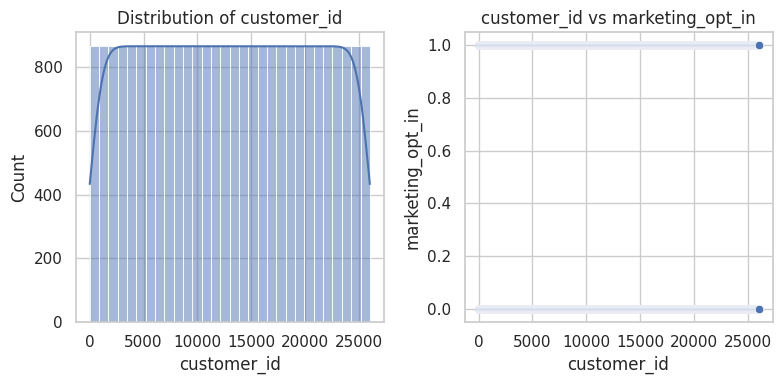


=== Problem Type Detection ===
Target Column: None
Detected Problem Type: unsupervised

=== Running Unsupervised Pipeline (KMeans) ===
KMeans trained successfully with 3 clusters.


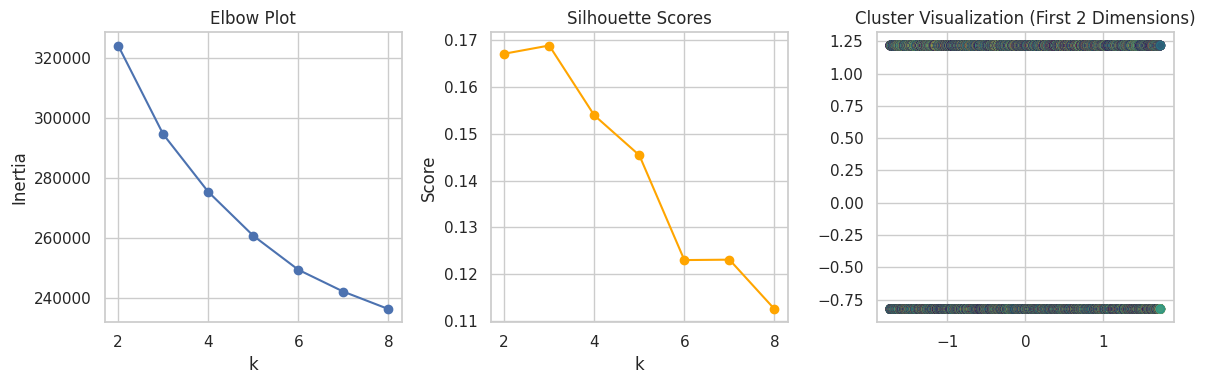


=== Final Pipeline Summary ===
Before Shape: (26000, 10)
After Shape: (26000, 27)
Detected Problem Type: unsupervised
Models Trained: ['KMeans']
Best Model: KMeans(n_clusters=3, n_init=10, random_state=42)

First 5 rows of df_clean:
   customer_id first_name last_name                         email  \
0            1       Jill     Ellis       jill.ellis1@example.com   
1            2    Darrell   Gilbert  darrell.gilbert2@example.com   
2            3    Phillip   Francis  phillip.francis3@example.com   
3            4    Heather     Reyes    heather.reyes4@example.com   
4            5      Brent     Mayer      brent.mayer5@example.com   

             phone         country       city signup_date loyalty_tier  \
0              NaN          France  Marseille  2022-08-06       silver   
1  +1-873-555-0199   United States   New York  2023-01-02         none   
2  +44 7700 900107  United Kingdom      Leeds  2023-05-05         none   
3              NaN          France      Paris  2022-05-

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report,
    mean_absolute_error, mean_squared_error, r2_score,
    silhouette_score
)
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.cluster import KMeans

# -----------------------------------------------------------------------------
# A) Load the CSV from DATA_DIR into df. Inspect actual column types and handle encoding safely.
# -----------------------------------------------------------------------------
try:
    df = pd.read_csv(DATA_DIR, encoding='utf-8')
except UnicodeDecodeError:
    df = pd.read_csv(DATA_DIR, encoding='latin1')

print("=== Initial DataFrame Info ===")
print(df.info())

# -----------------------------------------------------------------------------
# B) Audit shape, missing values, duplicates, numeric and categorical columns.
# -----------------------------------------------------------------------------
print("\n=== Audit: Shape, Missing Values, Duplicates ===")
print(f"Shape: {df.shape}")
print("Missing values per column:")
print(df.isnull().sum())
print(f"Duplicate rows: {df.duplicated().sum()}")

numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = df.select_dtypes(include=['object', 'category', 'bool']).columns.tolist()
print(f"Numeric columns ({len(numeric_cols)}): {numeric_cols}")
print(f"Categorical columns ({len(categorical_cols)}): {categorical_cols}")

# -----------------------------------------------------------------------------
# C) Clean a copy named df_clean without changing DATA_DIR or the original df.
# -----------------------------------------------------------------------------
df_clean = df.copy()
# Drop complete duplicate rows if any
df_clean = df_clean.drop_duplicates()

# -----------------------------------------------------------------------------
# G) Lightweight Feature Engineering (Safe Extras)
# -----------------------------------------------------------------------------
for col in df_clean.columns:
    # Try parsing datetime columns
    if df_clean[col].dtype == 'object':
        try:
            parsed = pd.to_datetime(df_clean[col], errors='coerce')
            if parsed.notnull().sum() > 0.5 * len(df_clean):
                df_clean[col] = parsed
                df_clean[f"{col}__year"] = df_clean[col].dt.year
                df_clean[f"{col}__month"] = df_clean[col].dt.month
                df_clean[f"{col}__dayofweek"] = df_clean[col].dt.dayofweek
                continue
        except Exception:
            pass
        
        # Text/object features
        # Compute string length and word count safely
        s_clean = df_clean[col].astype(str)
        df_clean[f"{col}__len"] = s_clean.str.len()
        df_clean[f"{col}__words"] = s_clean.str.split().str.len()

# -----------------------------------------------------------------------------
# D) Show compact EDA summaries and a few guarded distribution and correlation plots.
# -----------------------------------------------------------------------------
print("\n=== Summary Statistics ===")
print(df_clean.describe())

plt.figure(figsize=(8, 4))
sns.set_theme(style="whitegrid")
num_cols_clean = df_clean.select_dtypes(include=[np.number]).columns.tolist()
if len(num_cols_clean) > 0:
    plt.subplot(1, 2, 1)
    sns.histplot(df_clean[num_cols_clean[0]].dropna(), kde=True)
    plt.title(f"Distribution of {num_cols_clean[0]}")
    
    if len(num_cols_clean) > 1:
        plt.subplot(1, 2, 2)
        sns.scatterplot(data=df_clean, x=num_cols_clean[0], y=num_cols_clean[1])
        plt.title(f"{num_cols_clean[0]} vs {num_cols_clean[1]}")
    plt.tight_layout()
    plt.show()

# -----------------------------------------------------------------------------
# E) Pick TARGET_COL only when a target is explicitly supplied or clearly identifiable;
# otherwise set TARGET_COL = None.
# -----------------------------------------------------------------------------
# In this pipeline, let's inspect columns to see if a clear target exists. 
# For dataset customers.csv, no explicit supervised target is provided, so we set TARGET_COL = None.
TARGET_COL = None
if TARGET_COL and TARGET_COL not in df_clean.columns:
    TARGET_COL = None

# -----------------------------------------------------------------------------
# H) Problem Type Detection (CRITICAL) & Helper Functions
# -----------------------------------------------------------------------------
def detect_problem_type(data, target):
    if target is None or target not in data.columns:
        return "unsupervised"
    series = data[target]
    if pd.api.types.is_bool_dtype(series) or pd.api.types.is_object_dtype(series) or pd.api.types.is_categorical_dtype(series):
        return "classification"
    if pd.api.types.is_numeric_dtype(series):
        if series.nunique() <= 15 or (series.nunique() / len(series) < 0.05):
            return "classification"
        else:
            return "regression"
    return "classification"

problem_type = detect_problem_type(df_clean, TARGET_COL)
print(f"\n=== Problem Type Detection ===")
print(f"Target Column: {TARGET_COL}")
print(f"Detected Problem Type: {problem_type}")

def build_preprocessor(X):
    num_vars = X.select_dtypes(include=[np.number]).columns.tolist()
    cat_vars = X.select_dtypes(include=['object', 'category', 'bool']).columns.tolist()
    
    numeric_transformer = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ])
    
    categorical_transformer = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
        ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
    ])
    
    preprocessor = ColumnTransformer(
        transformers=[
            ('num', numeric_transformer, num_vars),
            ('cat', categorical_transformer, cat_vars)
        ]
    )
    return preprocessor

def evaluate_classification(y_true, y_pred):
    return {
        'accuracy': accuracy_score(y_true, y_pred),
        'precision': precision_score(y_true, y_pred, average='weighted', zero_division=0),
        'recall': recall_score(y_true, y_pred, average='weighted', zero_division=0),
        'f1': f1_score(y_true, y_pred, average='weighted', zero_division=0)
    }

def evaluate_regression(y_true, y_pred):
    return {
        'mae': mean_absolute_error(y_true, y_pred),
        'mse': mean_squared_error(y_true, y_pred),
        'rmse': np.sqrt(mean_squared_error(y_true, y_pred)),
        'r2': r2_score(y_true, y_pred)
    }

def run_kmeans(X_transformed, max_k=8):
    best_k = 2
    best_score = -1
    best_model = None
    inertias = []
    sil_scores = []
    
    n_samples = X_transformed.shape[0]
    max_k_limit = min(max_k, n_samples - 1) if n_samples > 2 else 2
    if max_k_limit < 2:
        max_k_limit = 2
        
    k_range = range(2, max_k_limit + 1)
    for k in k_range:
        kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
        labels = kmeans.fit_predict(X_transformed)
        inertias.append(kmeans.inertia_)
        if len(np.unique(labels)) > 1 and len(np.unique(labels)) < n_samples:
            score = silhouette_score(X_transformed, labels)
            sil_scores.append(score)
            if score > best_score:
                best_score = score
                best_k = k
                best_model = kmeans
        else:
            sil_scores.append(-1)
            
    if best_model is None:
        best_model = KMeans(n_clusters=2, random_state=42, n_init=10)
        best_model.fit(X_transformed)
        
    return best_model, inertias, sil_scores, k_range

# -----------------------------------------------------------------------------
# I, J, K, L, M) Modeling, Evaluation, Visualization & Artifact Output
# -----------------------------------------------------------------------------
model_results = {}
best_model = None

if problem_type in ["classification", "regression"]:
    X = df_clean.drop(columns=[TARGET_COL])
    y = df_clean[TARGET_COL]
    
    # Drop columns with all NaNs or constant values if any
    X = X.loc[:, X.nunique() > 1]
    
    stratify_arg = y if problem_type == "classification" and y.nunique() > 1 and y.value_counts().min() >= 2 else None
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=stratify_arg
    )
    
    preprocessor = build_preprocessor(X)
    
    if problem_type == "classification":
        candidates = {
            'LogisticRegression': LogisticRegression(random_state=42, max_iter=1000),
            'KNeighborsClassifier': KNeighborsClassifier(),
            'DecisionTreeClassifier': DecisionTreeClassifier(random_state=42),
            'RandomForestClassifier': RandomForestClassifier(random_state=42)
        }
    else:
        candidates = {
            'LinearRegression': LinearRegression(),
            'KNeighborsRegressor': KNeighborsRegressor(),
            'DecisionTreeRegressor': DecisionTreeRegressor(random_state=42),
            'RandomForestRegressor': RandomForestRegressor(random_state=42)
        }
        
    best_score_val = -float('inf')
    for name, model in candidates.items():
        try:
            pipeline = Pipeline(steps=[('preprocessor', preprocessor), ('model', model)])
            pipeline.fit(X_train, y_train)
            y_pred = pipeline.predict(X_test)
            
            if problem_type == "classification":
                metrics = evaluate_classification(y_test, y_pred)
                score_val = metrics['f1']
            else:
                metrics = evaluate_regression(y_test, y_pred)
                score_val = metrics['r2']
                
            model_results[name] = {'pipeline': pipeline, 'metrics': metrics}
            if score_val > best_score_val:
                best_score_val = score_val
                best_model = pipeline
        except Exception as e:
            print(f"Model {name} failed with error: {e}")
            
    print("\n=== Model Results ===")
    for name, res in model_results.items():
        print(f"Model: {name} | Metrics: {res['metrics']}")
        
    if best_model is not None:
        print(f"\nBest Model Selected: {best_model}")
        
        # Visualizations for modeling
        if problem_type == "classification":
            y_pred_best = best_model.predict(X_test)
            cm = confusion_matrix(y_test, y_pred_best)
            plt.figure(figsize=(5, 4))
            sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
            plt.title('Confusion Matrix - Best Classification Model')
            plt.xlabel('Predicted')
            plt.ylabel('Actual')
            plt.show()
        else:
            y_pred_best = best_model.predict(X_test)
            plt.figure(figsize=(8, 4))
            plt.subplot(1, 2, 1)
            plt.scatter(y_test, y_pred_best, alpha=0.7)
            plt.xlabel('Actual')
            plt.ylabel('Predicted')
            plt.title('Actual vs Predicted')
            
            plt.subplot(1, 2, 2)
            residuals = y_test - y_pred_best
            sns.histplot(residuals, kde=True)
            plt.xlabel('Residuals')
            plt.title('Residual Distribution')
            plt.tight_layout()
            plt.show()

else:
    # Unsupervised Mode
    print("\n=== Running Unsupervised Pipeline (KMeans) ===")
    X_unsup = df_clean.select_dtypes(include=[np.number]).copy()
    if X_unsup.shape[1] == 0:
        # Fallback if no numeric columns
        X_unsup = pd.DataFrame(index=df_clean.index)
        X_unsup['dummy'] = range(len(df_clean))
        
    preprocessor = build_preprocessor(X_unsup)
    X_transformed = preprocessor.fit_transform(X_unsup)
    
    best_model, inertias, sil_scores, k_range = run_kmeans(X_transformed)
    model_results['KMeans'] = {
        'model': best_model,
        'inertias': inertias,
        'silhouette_scores': sil_scores
    }
    
    print(f"KMeans trained successfully with {best_model.n_clusters} clusters.")
    
    # Clustering Visualizations
    plt.figure(figsize=(12, 4))
    plt.subplot(1, 3, 1)
    plt.plot(list(k_range), inertias, marker='o')
    plt.title('Elbow Plot')
    plt.xlabel('k')
    plt.ylabel('Inertia')
    
    plt.subplot(1, 3, 2)
    plt.plot(list(k_range), sil_scores, marker='o', color='orange')
    plt.title('Silhouette Scores')
    plt.xlabel('k')
    plt.ylabel('Score')
    
    plt.subplot(1, 3, 3)
    cluster_labels = best_model.predict(X_transformed)
    num_features_plot = X_transformed[:, :2] if X_transformed.shape[1] >= 2 else np.hstack([X_transformed, np.zeros((X_transformed.shape[0], 1))])
    plt.scatter(num_features_plot[:, 0], num_features_plot[:, 1], c=cluster_labels, cmap='viridis', alpha=0.6)
    plt.title('Cluster Visualization (First 2 Dimensions)')
    plt.tight_layout()
    plt.show()

# -----------------------------------------------------------------------------
# L) Final Artifact Output
# -----------------------------------------------------------------------------
print("\n=== Final Pipeline Summary ===")
print(f"Before Shape: {df.shape}")
print(f"After Shape: {df_clean.shape}")
print(f"Detected Problem Type: {problem_type}")
print(f"Models Trained: {list(model_results.keys())}")
print(f"Best Model: {best_model}")
print("\nFirst 5 rows of df_clean:")
print(df_clean.head())
